# Real observations: similar epistemic uncertainty, different acquisitions?
## UCI Adult — controlled revelation of recorded sector and income

The analytic counterexample used invented probabilities. This experiment instead uses **recorded employment sector and recorded income labels** from UCI Adult. We do not synthesize labels, flip outcomes, choose new mixture proportions, or assign arbitrary source identities.

We do control which fields are visible and how many observations are initially available. We look for two information states with nearly equal predictive epistemic MI for the same population target, but opposite preferred acquisitions. The official training file supplies candidate states. Only after selecting the pair do we evaluate acquisitions using the official test file.

This is a **controlled empirical-population resampling study**, not a prospective data-collection trial, a new image benchmark, or an exact equality proof. The previous theorem supplies exact equality; here similarity has a prespecified tolerance. Success is not forced: no qualifying pair or a failed held-out reversal must be reported.

All output is saved in a fresh `workbook/adult_acquisition_<UTC>/` folder. Every table and figure is accompanied by assumptions and interpretation. No previous notebook is changed.

### Sources, dataset choice and scope

- [UCI Adult official documentation](https://archive.ics.uci.edu/dataset/2/adult) and [download](https://archive.ics.uci.edu/static/public/2/adult.zip): recorded census-derived variables, official files, missing-value conventions and provenance. The archive hash is saved.
- [WILDS dataset documentation](https://wilds.stanford.edu/datasets/): considered for later image experiments with actual domain metadata. No WILDS data are used here.
- Hüllermeier & Waegeman, [uncertainty concepts](https://doi.org/10.1007/s10994-021-05946-3): predictive epistemic MI and uncertainty over probabilities.
- [Probly](https://github.com/pwhofman/probly): independently check the MI representation on posterior samples for the selected pair.
- Local `acquisition_counterexample.ipynb`: the exact toy proof being tested observationally; `real/beta_acquisition.py`: equations implemented below.

The four cached image datasets contain images and one class label, but no separate writer/hospital/domain identity. Manufacturing such a field would preserve a synthetic mechanism. Adult has distinct, co-recorded sector and income fields. Sector is a **population stratum**, not acquisition provenance or a causal treatment. We make no causal claims or recommendations about individuals.

This pilot models only sector and income. Other census features are deliberately excluded, so it does not establish that unlabeled features cannot help. It does not train or evaluate DAPPr. The claim under test is the acquisition sufficiency of predictive epistemic summaries, not a defect in a specific neural model.

In [1]:
# Goal: freeze the protocol, matching thresholds and random seeds before inspecting states.
from pathlib import Path
import sys,json,hashlib,zipfile,io,shutil,importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if not (ROOT/'real/beta_acquisition.py').exists():ROOT=ROOT/'Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS'
sys.path.insert(0,str(ROOT))
from real.beta_acquisition import *
SEED=20261029
N_IDENTITIES=[0,2,8,32,128,512]
N_LABELS_PER_SOURCE=[2,8,32,128,512]
STATE_REPEATS=20
VALIDATION_REPEATS=4000
BUDGETS=[0,1,2,4,8,16,32,64,128]
MI_RELATIVE_TOLERANCE=.01
MEAN_ABSOLUTE_TOLERANCE=.02
VARIANCE_RELATIVE_TOLERANCE=.10
ACTION_MARGIN=2.
QUADRATURE_ORDER=24
ARCHIVE=ROOT/'data/adult/adult.zip'
assert ARCHIVE.exists(),'Download the official UCI Adult archive before running.'
RUN_DIR=ROOT/'workbook'/('adult_acquisition_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ'))
RUN_DIR.mkdir(parents=True,exist_ok=False)
plt.rcdefaults()
protocol=dict(seed=SEED,n_identities=N_IDENTITIES,n_labels_per_source=N_LABELS_PER_SOURCE,state_repeats=STATE_REPEATS,
    validation_repeats=VALIDATION_REPEATS,budgets=BUDGETS,mi_relative_tolerance=MI_RELATIVE_TOLERANCE,
    mean_absolute_tolerance=MEAN_ABSOLUTE_TOLERANCE,variance_relative_tolerance=VARIANCE_RELATIVE_TOLERANCE,
    action_margin=ACTION_MARGIN,prior='independent Beta(1,1) for W,Theta0,Theta1',quadrature_order=QUADRATURE_ORDER,
    source='private versus public employment (Federal/Local/State-gov)',target='unweighted income >50K prevalence in retained population',
    matching_rule='min relative MI discrepancy subject to fixed tolerances and opposite >=2x action preferences; tie by state IDs',
    archive_url='https://archive.ics.uci.edu/static/public/2/adult.zip',archive_sha256=hashlib.sha256(ARCHIVE.read_bytes()).hexdigest())
(RUN_DIR/'protocol.json').write_text(json.dumps(protocol,indent=2))
print('Protocol saved before candidate generation:',RUN_DIR)


Protocol saved before candidate generation: /home/mtleao/projects/Concept_Disentaglement/Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS/workbook/adult_acquisition_20261029T214309638018Z


### 1. Real source and target, no simulated labels

Retain records with workclass `Private`, `Federal-gov`, `Local-gov` or `State-gov`. Set S=0 for private and S=1 for public. Exclude other workclasses and missing sector; record all exclusions. Set Y=1 exactly when the recorded income label is `>50K`. Missing values in unused features do not exclude a record.

The target is $T=P(Y=1)$ in this retained **unweighted record population**, not census-weighted national income prevalence. The `fnlwgt` field is not used. Both states concern this same target. We keep the original train/test file boundaries and record line IDs for every acquisition.

Training records generate initial states by sampling with replacement; held-out records validate acquisition responses by the same empirical-population resampling convention. Repeated records are possible and flagged through saved row IDs. This makes each requested outcome an independent draw from the specified empirical population; it does not create new independent people. Cross-channel row IDs are available only to the audit, not the inference engine.

Only training-file summaries are shown before pair selection. No test labels choose a pair, prior, tolerance or source definition.

In [2]:
# Goal: load only the training records now; defer all test-population inspection until after matching.
COLUMNS=['age','workclass','fnlwgt','education','education_num','marital_status','occupation','relationship','race','sex',
         'capital_gain','capital_loss','hours_per_week','native_country','income']
def load_records(filename):
    with zipfile.ZipFile(ARCHIVE) as z:
        raw=z.read(filename).decode('utf-8')
    frame=pd.read_csv(io.StringIO(raw),names=COLUMNS,skipinitialspace=True,comment='|',skip_blank_lines=True)
    frame['record_id']=np.arange(len(frame))
    allowed=['Private','Federal-gov','Local-gov','State-gov']
    retained=frame.workclass.isin(allowed)
    f=frame.loc[retained,['record_id','workclass','income']].copy()
    f['income']=f.income.str.strip().str.rstrip('.')
    assert f.income.isin(['>50K','<=50K']).all()
    f['source']=(f.workclass!='Private').astype(int)
    f['target']=(f.income=='>50K').astype(int)
    return f.reset_index(drop=True),dict(file=filename,total=len(frame),retained=int(retained.sum()),excluded=int((~retained).sum()))
train,train_audit=load_records('adult.data')
train.to_csv(RUN_DIR/'training_record_index.csv',index=False)
display(pd.crosstab(train.source,train.target))
print(train_audit)


target,0,1
source,,
0,17733,4963
1,3010,1341


{'file': 'adult.data', 'total': 32561, 'retained': 27047, 'excluded': 5514}


### 2. Model the same target under different amounts of observed information

Let $W=P(S=1)$, $\Theta_s=P(Y=1\mid S=s)$ and $T=(1-W)\Theta_0+W\Theta_1$. Start with independent Beta(1,1) priors. Identity observations update W; target labels sampled from a known source update its target rate. No other field is revealed. Source selection for reference labels is supplied by a stratified sampling service, not inferred for free from the deployment sample.

For Beta(a,b), mean $m=a/(a+b)$ and variance $v=m(1-m)/(a+b+1)$. Independence gives

$$E[T]=(1-m_w)m_0+m_wm_1,$$
$$V_T=((1-m_w)^2+v_w)v_0+(m_w^2+v_w)v_1+v_w(m_1-m_0)^2.$$

The predictive epistemic score for the next binary target is $U=h(E[T])-E[h(T)]$, evaluated by product Gauss–Jacobi quadrature. It concerns this population target, not a per-image score being compared against an unrelated population estimand.

Compare equal-cost, one-observation acquisitions:

- **Identity:** reveal S for a random deployment record; hide income.
- **Reference target label:** select source 0 or 1 by a fair coin, then reveal Y from that source; the stratum is known by design. This rule is fixed, not optimized on held-out labels.

By the law of total variance, their exact expected reductions in squared-error Bayes risk are

$$V_{ID}=(m_1-m_0)^2v_w/(a_w+b_w+1),$$
$$V_{label}=\tfrac12[(1-m_w)^2v_0/(a_0+b_0+1)+m_w^2v_1/(a_1+b_1+1)].$$

The mean/risk/MI summarize predictive uncertainty. Action values additionally use **where that uncertainty resides** and the acquisition likelihood. Four unit tests check these formulas against direct posterior outcome enumeration and independent Monte Carlo moments.

### 3. Find near-matched states using training observations only

For every declared identity/label budget combination, draw 20 initial observation states. Each posterior is updated from actual sampled sector/income entries. The scan covers both identity-scarce and label-scarce information states; we do not manufacture a desired posterior after inspecting test outcomes.

A qualifying pair must have opposite optimal actions with at least a twofold value margin, MI difference at most 1% of their average MI, mean-target difference at most 0.02, and target-variance difference at most 10% of their average variance. Among qualifying pairs, select the smallest relative MI difference, then state IDs. Save the entire candidate catalogue and number of matches; this is a selected counterexample search, not an estimate of prevalence.

If no pair meets the thresholds, the result is a failure to find the prespecified match. Thresholds will not be relaxed automatically.

In [3]:
# Goal: construct empirically grounded posterior states and select a pair without test access.
rng=np.random.default_rng(SEED)
source_positions={s:np.flatnonzero(train.source.to_numpy()==s) for s in [0,1]}
state_rows=[];observation_ids={}
for ni in N_IDENTITIES:
    for nl in N_LABELS_PER_SOURCE:
        for repeat in range(STATE_REPEATS):
            state_id=len(state_rows)
            identity_ix=rng.integers(0,len(train),size=ni)
            label_ix=[rng.choice(source_positions[s],size=nl,replace=True) for s in [0,1]]
            source_success=int(train.source.iloc[identity_ix].sum())
            label_success=[int(train.target.iloc[ix].sum()) for ix in label_ix]
            shapes=np.array([[1+source_success,1+ni-source_success]]+[[1+k,1+nl-k] for k in label_success],dtype=float)
            mean,var=moments(shapes);vid,vlab=action_values(shapes)
            mi=epistemic_mi(shapes,QUADRATURE_ORDER)
            state_rows.append(dict(state_id=state_id,n_identity=ni,n_label_per_source=nl,repeat=repeat,
                mean=float(mean),variance=float(var),epistemic_mi=mi,value_identity=float(vid),value_label=float(vlab),
                shapes=json.dumps(shapes.tolist())))
            observation_ids[str(state_id)]={
                'identity_record_ids':train.record_id.iloc[identity_ix].tolist(),
                'source0_label_record_ids':train.record_id.iloc[label_ix[0]].tolist(),
                'source1_label_record_ids':train.record_id.iloc[label_ix[1]].tolist()}
states=pd.DataFrame(state_rows)
states.to_csv(RUN_DIR/'candidate_states.csv',index=False)
(RUN_DIR/'initial_observation_ids.json').write_text(json.dumps(observation_ids))
a=states[states.value_identity>=ACTION_MARGIN*states.value_label]
b=states[states.value_label>=ACTION_MARGIN*states.value_identity]
pairs=[]
for _,x in a.iterrows():
    for _,y in b.iterrows():
        mi_rel=abs(x.epistemic_mi-y.epistemic_mi)/((x.epistemic_mi+y.epistemic_mi)/2)
        var_rel=abs(x.variance-y.variance)/((x.variance+y.variance)/2)
        if mi_rel<=MI_RELATIVE_TOLERANCE and abs(x['mean']-y['mean'])<=MEAN_ABSOLUTE_TOLERANCE and var_rel<=VARIANCE_RELATIVE_TOLERANCE:
            pairs.append(dict(identity_state=int(x.state_id),label_state=int(y.state_id),mi_relative_difference=mi_rel,
                mean_difference=abs(x['mean']-y['mean']),variance_relative_difference=var_rel))
pair_table=pd.DataFrame(pairs)
if len(pair_table)==0:
    (RUN_DIR/'RESULTS.md').write_text('No pair satisfied the prespecified matching criteria. No held-out confirmation was attempted. See candidate_states.csv and protocol.json.')
    raise RuntimeError('No prespecified matched pair: preserve this negative result; do not silently relax tolerances.')
pair_table=pair_table.sort_values(['mi_relative_difference','identity_state','label_state'])
pair_table.to_csv(RUN_DIR/'qualifying_pairs.csv',index=False)
chosen=pair_table.iloc[0]
selected=states.set_index('state_id').loc[[int(chosen.identity_state),int(chosen.label_state)]].reset_index()
selected['state_role']=['identity_preferred','label_preferred']
selected['mi_quadrature_48']=[epistemic_mi(np.array(json.loads(r.shapes)),48) for _,r in selected.iterrows()]
assert np.max(abs(selected.epistemic_mi-selected.mi_quadrature_48))<1e-7
selected.to_csv(RUN_DIR/'selected_states.csv',index=False)
print('Candidate states:',len(states),'| qualifying pairs:',len(pair_table))
display(selected)
display(chosen.to_frame('selected_pair'))


Candidate states: 600 | qualifying pairs: 60


,state_id,n_identity,n_label_per_source,repeat,mean,variance,epistemic_mi,value_identity,value_label,shapes,state_role,mi_quadrature_48
0,267,8,128,7,0.287692,0.001203,0.002949,1.126705e-05,0.000004,"[[2.0, 8.0], [35.0, 95.0], [47.0, 83.0]]",identity_preferred,0.002949
1,363,32,128,3,0.292081,0.001218,0.002949,2.968817e-07,0.000005,"[[5.0, 29.0], [39.0, 91.0], [32.0, 98.0]]",label_preferred,0.002949


,selected_pair
identity_state,267.000000
label_state,363.000000
mi_relative_difference,0.000011
mean_difference,0.004389
variance_relative_difference,0.012380


### 4. Independent representation check and a view of the full search

For the selected states, draw posterior W and target rates and pass the resulting Bernoulli distributions to Probly. This independently checks the numerical meaning of the reported epistemic MI. Quadrature remains the primary score because the matching tolerance should not be driven by Monte Carlo noise.

The plot shows every candidate state, with the two selected states highlighted. Nearby MI values with different action preferences are the empirical pattern under study. The full catalogue is retained so the pair is not presented as a randomly selected typical case.

,state_id,quadrature_mi,probly_sample_mi
0,267,0.002949,0.002954
1,363,0.002949,0.002951


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Failed to find font weight 300 for DejaVu Sans, now using 400.


findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Failed to find font weight 300 for DejaVu Sans, now using 400.


... (494 outputs left out)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


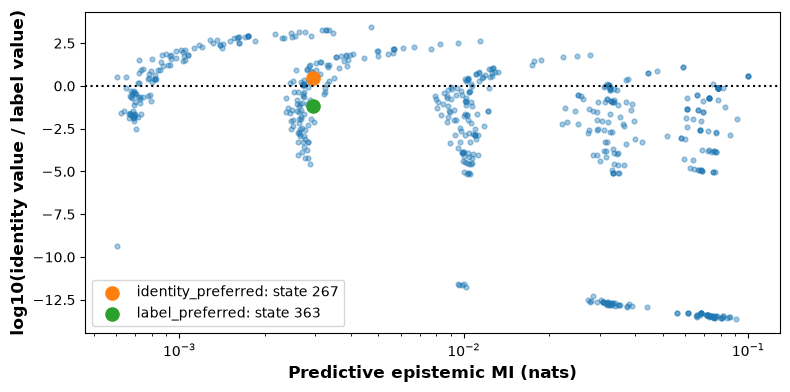

In [4]:
# Goal: audit the MI calculation with Probly and visualize all candidate states.
import torch
from probly.representation.distribution.torch_categorical import TorchProbabilityCategoricalDistribution,TorchCategoricalDistributionSample
from probly.quantification import quantify
checks=[]
for _,row in selected.iterrows():
    shape=np.array(json.loads(row.shapes));rngcheck=np.random.default_rng(SEED+int(row.state_id))
    draws=rngcheck.beta(shape[:,0],shape[:,1],size=(200000,3))
    t=(1-draws[:,0])*draws[:,1]+draws[:,0]*draws[:,2]
    p=torch.tensor(np.column_stack([1-t,t]),dtype=torch.float64)
    out=TorchCategoricalDistributionSample(tensor=TorchProbabilityCategoricalDistribution(p),sample_dim=0)
    checks.append(dict(state_id=int(row.state_id),quadrature_mi=row.epistemic_mi,probly_sample_mi=float(quantify(out).epistemic)))
check_table=pd.DataFrame(checks);check_table.to_csv(RUN_DIR/'probly_check.csv',index=False)
display(check_table)
fig,ax=plt.subplots(figsize=(8,4))
ratio=np.log10((states.value_identity+1e-16)/(states.value_label+1e-16))
ax.scatter(states.epistemic_mi,ratio,s=12,alpha=.4)
for _,row in selected.iterrows():
    ax.scatter(row.epistemic_mi,np.log10(row.value_identity/row.value_label),s=90,label=f'{row.state_role}: state {row.state_id}')
ax.axhline(0,color='black',ls=':');ax.set(xscale='log',xlabel='Predictive epistemic MI (nats)',ylabel='log10(identity value / label value)')
ax.legend();fig.tight_layout()
for ext in ['png','pdf']:fig.savefig(RUN_DIR/f'candidate_search.{ext}',dpi=170,bbox_inches='tight')
plt.show()


### 5. Reveal held-out observations only after fixing the pair

Now load the official test file, using the same retention rule. The deployment target for empirical validation is its unweighted income-positive proportion. Inspect sector frequencies and source-specific label rates to document train/test differences; do not refit the pair or matching thresholds.

Two distinct validations follow:

1. **Exact one-step empirical expectation:** enumerate every possible outcome with frequencies from held-out records, update the selected posterior, and compute expected squared error against held-out prevalence. This need not agree with the model's expected risk reduction: the initial posterior can be biased or accidentally close to truth.
2. **Paired acquisition trajectories:** sample actual held-out record IDs with replacement for each channel, reveal only the requested field, and update honestly. Both selected states receive the same channel streams. Use 4,000 repetitions and equal observation budgets.

Primary empirical confirmation is the sign of the **exact one-step squared-error advantage**: identities should win in the identity-preferred state and labels in the label-preferred state. Larger-budget curves are secondary. Failure of this held-out reversal must be reported even if posterior action values reverse by construction.

In [5]:
# Goal: evaluate a prespecified reversal on real held-out outcomes, distinguishing belief and error.
test,test_audit=load_records('adult.test')
test.to_csv(RUN_DIR/'heldout_record_index.csv',index=False)
(RUN_DIR/'record_filter_audit.json').write_text(json.dumps([train_audit,test_audit],indent=2))
truth=float(test.target.mean());w_test=float(test.source.mean())
theta_test=[float(test[test.source==s].target.mean()) for s in [0,1]]
population=pd.DataFrame([dict(split=split,n=len(f),public_share=float(f.source.mean()),target_rate=float(f.target.mean()),
    theta0=float(f[f.source==0].target.mean()),theta1=float(f[f.source==1].target.mean())) for split,f in [('train',train),('heldout',test)]])
population.to_csv(RUN_DIR/'population_rates.csv',index=False);display(population)
empirical=[]
for _,row in selected.iterrows():
    shape=np.array(json.loads(row.shapes));initial_mean,initial_var=moments(shape)
    for action in ['source_id','reference_label']:
        groups=[(None,1.,w_test)] if action=='source_id' else [(0,.5,theta_test[0]),(1,.5,theta_test[1])]
        error_after=0.;variance_after=0.
        for source,weight,rate in groups:
            for outcome,prob in [(0,1-rate),(1,rate)]:
                mean,var=moments(update(shape,action,outcome,source))
                error_after+=weight*prob*(mean-truth)**2;variance_after+=weight*prob*var
        empirical.append(dict(state_id=int(row.state_id),state_role=row.state_role,action=action,
            initial_squared_error=float((initial_mean-truth)**2),expected_squared_error=float(error_after),
            empirical_mse_reduction=float((initial_mean-truth)**2-error_after),
            empirical_variance_reduction=float(initial_var-variance_after),
            model_variance_reduction=float(row.value_identity if action=='source_id' else row.value_label)))
empirical=pd.DataFrame(empirical);empirical.to_csv(RUN_DIR/'heldout_exact_one_step.csv',index=False)
display(empirical)


,split,n,public_share,target_rate,theta0,theta1
0,train,27047,0.160868,0.233076,0.218673,0.308205
1,heldout,13408,0.163932,0.231280,0.216236,0.308007


,state_id,state_role,action,initial_squared_error,expected_squared_error,empirical_mse_reduction,empirical_variance_reduction,model_variance_reduction
0,267,identity_preferred,source_id,0.003182,0.003158,0.000024,0.000008,1.126705e-05
1,267,identity_preferred,reference_label,0.003182,0.003163,0.000019,0.000004,3.937716e-06
2,363,label_preferred,source_id,0.003697,0.003694,0.000003,0.000001,2.968817e-07
3,363,label_preferred,reference_label,0.003697,0.003672,0.000025,0.000005,4.568202e-06


### 6. Observe the acquisition curves, including possible failures

These curves use only recorded field values from held-out records. Repeated empirical-population draws assess acquisition variation conditional on this fixed dataset; they do not quantify uncertainty about a new census population.

For each repeat, initial state, channel and budget, save the posterior parameters, mean, variance and actual squared error. Every drawn record ID and source choice is archived. Report paired differences between channels with Monte Carlo standard errors. The error bars are simulation-error estimates, not population confidence intervals.

A decreasing posterior variance alone does not establish that the target estimate improved. The squared-error panel is essential. No neural predictor is held frozen and then penalized for not responding: every acquired observation updates the appropriate posterior component.

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


... (2,722 outputs left out)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


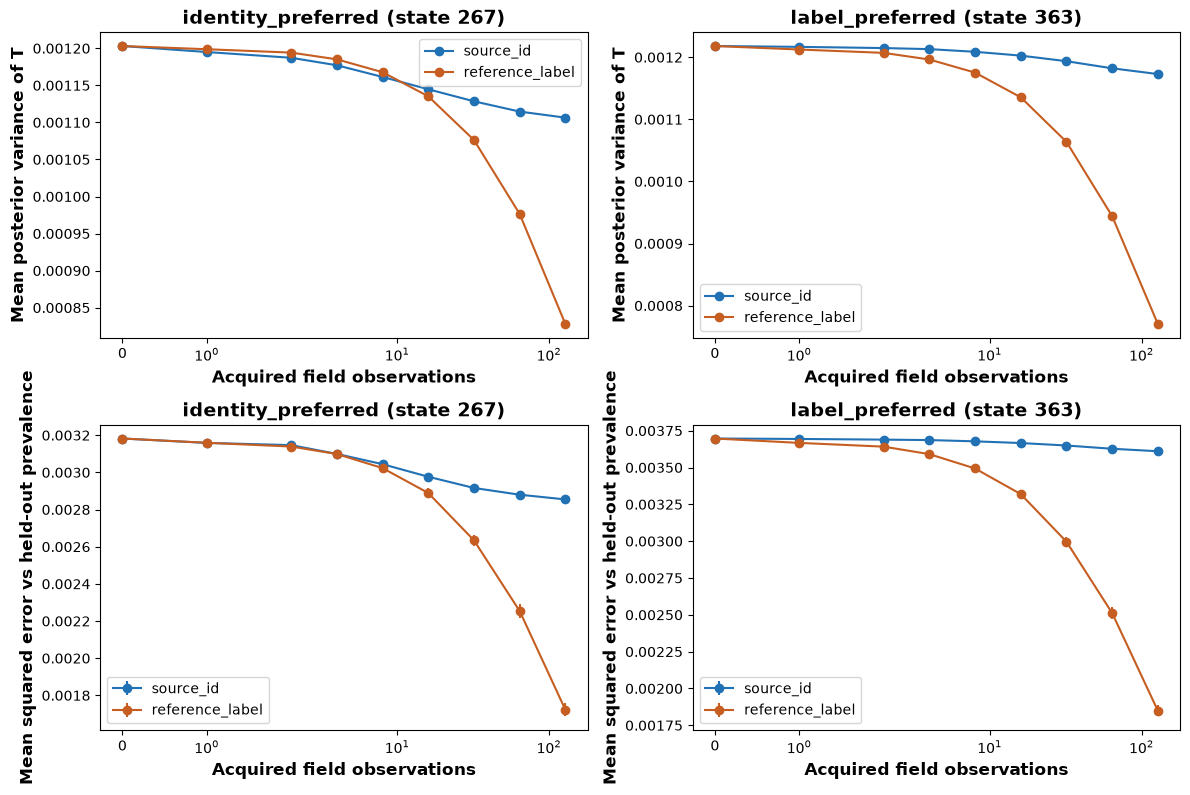

,index,state_id,state_role,n,mean,std,mc_se
1,1,267,identity_preferred,1,-5.491730e-07,0.000423,0.000007
6,6,267,identity_preferred,32,2.816787e-04,0.001102,0.000017
8,8,267,identity_preferred,128,1.131836e-03,0.001219,0.000019
10,10,363,label_preferred,1,2.678805e-05,0.000249,0.000004
15,15,363,label_preferred,32,6.527506e-04,0.001121,0.000018
17,17,363,label_preferred,128,1.760916e-03,0.001288,0.000020


In [6]:
# Goal: replay paired field acquisitions from held-out records and save all observations.
rngval=np.random.default_rng(SEED+9000);bmax=max(BUDGETS)
identity_positions=rngval.integers(0,len(test),size=(VALIDATION_REPEATS,bmax))
label_sources=rngval.integers(0,2,size=(VALIDATION_REPEATS,bmax))
label_positions=np.empty_like(label_sources)
for s in [0,1]:
    mask=label_sources==s;pool=np.flatnonzero(test.source.to_numpy()==s)
    label_positions[mask]=rngval.choice(pool,size=int(mask.sum()),replace=True)
identity_outcomes=test.source.to_numpy()[identity_positions]
label_outcomes=test.target.to_numpy()[label_positions]
np.savez_compressed(RUN_DIR/'heldout_acquisitions.npz',identity_record_ids=test.record_id.to_numpy()[identity_positions],
    label_record_ids=test.record_id.to_numpy()[label_positions],label_sources=label_sources,
    identity_outcomes=identity_outcomes,label_outcomes=label_outcomes)
trajectory=[]
for _,row in selected.iterrows():
    initial=np.array(json.loads(row.shapes))
    for action in ['source_id','reference_label']:
        shapes=np.broadcast_to(initial,(VALIDATION_REPEATS,3,2)).copy()
        for n in range(bmax+1):
            if n in BUDGETS:
                mean,var=moments(shapes)
                trajectory.append(pd.DataFrame(dict(state_id=int(row.state_id),state_role=row.state_role,action=action,n=n,
                    replicate=np.arange(VALIDATION_REPEATS),posterior_mean=mean,posterior_variance=var,squared_error=(mean-truth)**2)))
            if n==bmax:break
            components=np.zeros(VALIDATION_REPEATS,dtype=int) if action=='source_id' else 1+label_sources[:,n]
            outcomes=identity_outcomes[:,n] if action=='source_id' else label_outcomes[:,n]
            shapes[np.arange(VALIDATION_REPEATS),components,1-outcomes]+=1
trajectories=pd.concat(trajectory,ignore_index=True)
trajectories.to_csv(RUN_DIR/'acquisition_trajectories.csv.gz',index=False,compression='gzip')
summary=trajectories.groupby(['state_id','state_role','action','n'],as_index=False).agg(mean_variance=('posterior_variance','mean'),
    mean_squared_error=('squared_error','mean'),error_sd=('squared_error','std'))
summary['mc_se']=summary.error_sd/np.sqrt(VALIDATION_REPEATS)
summary.to_csv(RUN_DIR/'acquisition_summary.csv',index=False)
paired=trajectories.pivot(index=['state_id','state_role','n','replicate'],columns='action',values='squared_error').reset_index()
paired['identity_minus_label_error']=paired.source_id-paired.reference_label
contrasts=paired.groupby(['state_id','state_role','n'],as_index=False).identity_minus_label_error.agg(['mean','std']).reset_index()
contrasts['mc_se']=contrasts['std']/np.sqrt(VALIDATION_REPEATS)
contrasts.to_csv(RUN_DIR/'paired_error_contrasts.csv',index=False)
fig,axes=plt.subplots(2,2,figsize=(12,8),squeeze=False)
for col,(_,row) in enumerate(selected.iterrows()):
    for action,color in [('source_id','#2171b5'),('reference_label','#c65d21')]:
        f=summary[(summary.state_id==row.state_id)&(summary.action==action)]
        axes[0,col].plot(f.n,f.mean_variance,'o-',color=color,label=action)
        axes[1,col].errorbar(f.n,f.mean_squared_error,yerr=1.96*f.mc_se,fmt='o-',color=color,label=action)
    for ax in axes[:,col]:
        ax.set(xscale='symlog',xlabel='Acquired field observations',title=f'{row.state_role} (state {int(row.state_id)})');ax.legend()
    axes[0,col].set_ylabel('Mean posterior variance of T')
    axes[1,col].set_ylabel('Mean squared error vs held-out prevalence')
fig.tight_layout()
for ext in ['png','pdf']:fig.savefig(RUN_DIR/f'heldout_acquisition_curves.{ext}',dpi=170,bbox_inches='tight')
plt.show()
display(contrasts[contrasts.n.isin([1,32,128])])


### 7. Decide what the real-observation experiment supports

The matching search is exploratory within a frozen protocol. The selected states use real initial observations; sector/target outcomes are not invented. Nevertheless, the prior, observation masks, sampling channels and matching rules remain experimental choices.

The near-match is not the exact theorem: we should report its numerical discrepancy. The model-based action reversal is expected from selecting opposite preferences. The independent test is whether the held-out one-step error comparison also reverses. Posterior uncertainty, true estimation error and long-budget behavior may disagree; report that rather than interpreting any decreasing curve as success.

No general failure of DAPPr, no causal effect of employment sector, no population-wide prevalence estimate, and no claim that intervals alone solve acquisition choice follows. A successful outcome supports a practical analogue of the score-insufficiency mechanism under this finite real-record protocol. The full source/target likelihood remains essential.

In [7]:
# Goal: write a result-dependent conclusion and preserve all provenance and artifacts.
pivot=empirical.pivot(index='state_role',columns='action',values='expected_squared_error')
id_adv=float(pivot.loc['identity_preferred','reference_label']-pivot.loc['identity_preferred','source_id'])
label_adv=float(pivot.loc['label_preferred','source_id']-pivot.loc['label_preferred','reference_label'])
confirmed=id_adv>0 and label_adv>0
lines=['# UCI Adult real-observation acquisition experiment','',
    f'Candidate states: {len(states)}; qualifying near-matched pairs: {len(pair_table)}.',
    f'Selected MI relative difference: {float(chosen.mi_relative_difference):.6%}.',
    f'Selected predictive mean difference: {float(chosen.mean_difference):.6f}.',
    f'Selected target-variance relative difference: {float(chosen.variance_relative_difference):.6%}.','',
    '## Independent held-out primary endpoint','',
    f'Identity advantage in identity-preferred state (one-step expected squared error): {id_adv:.10g}.',
    f'Label advantage in label-preferred state (one-step expected squared error): {label_adv:.10g}.',
    f'Both advantages positive: {confirmed}.','',
    ('The prespecified held-out one-step reversal was observed.' if confirmed else 'The prespecified held-out one-step reversal was NOT confirmed; the selected model-based reversal alone is insufficient evidence of practical improvement.'),'',
    'Recorded sector and income values are real. Initial information budgets, independent Beta priors, field-revelation channels and empirical-population resampling are controlled.',
    'This is a selected near-match, not an exact equality proof or a prevalence estimate. Test labels did not choose the pair.',
    'Acquisition curves and paired error contrasts show whether effects persist beyond one observation. They must not be replaced by a posterior-variance-only conclusion.',
    'No DAPPr training or image experiment was performed here. SOURCES.md and the notebook document the theoretical foundations and limits.']
report='\n'.join(lines);(RUN_DIR/'RESULTS.md').write_text(report);display(Markdown(report))
notebook=json.loads((ROOT/'adult_acquisition_counterexample.ipynb').read_text())
(RUN_DIR/'SOURCES.md').write_text(''.join(notebook['cells'][1]['source']))
for c in notebook['cells']:
    if c['cell_type']=='code':c['outputs']=[];c['execution_count']=None
(RUN_DIR/'source_notebook.ipynb').write_text(json.dumps(notebook,indent=1))
for p in [ROOT/'real/beta_acquisition.py',ROOT/'tests/test_beta_acquisition.py',ROOT/'scripts/build_adult_acquisition_notebook.py']:
    shutil.copy2(p,RUN_DIR/p.name)
(RUN_DIR/'versions.json').write_text(json.dumps({p:importlib.metadata.version(p) for p in ['numpy','scipy','pandas','torch','probly']},indent=2))
(RUN_DIR/'README.md').write_text('Start with executed.ipynb and RESULTS.md. protocol.json was written before candidate generation. Candidate and selected states, every initial observation ID, held-out field acquisitions, posterior trajectories, matching discrepancies and paired error contrasts are saved. Source strata and income are genuine recorded fields; the acquisition study is controlled resampling. The runner adds executed.ipynb and artifact_manifest.json.')
print('Saved:',RUN_DIR)


# UCI Adult real-observation acquisition experiment

Candidate states: 600; qualifying near-matched pairs: 60.
Selected MI relative difference: 0.001136%.
Selected predictive mean difference: 0.004389.
Selected target-variance relative difference: 1.237978%.

## Independent held-out primary endpoint

Identity advantage in identity-preferred state (one-step expected squared error): 5.002314375e-06.
Label advantage in label-preferred state (one-step expected squared error): 2.22294568e-05.
Both advantages positive: True.

The prespecified held-out one-step reversal was observed.

Recorded sector and income values are real. Initial information budgets, independent Beta priors, field-revelation channels and empirical-population resampling are controlled.
This is a selected near-match, not an exact equality proof or a prevalence estimate. Test labels did not choose the pair.
Acquisition curves and paired error contrasts show whether effects persist beyond one observation. They must not be replaced by a posterior-variance-only conclusion.
No DAPPr training or image experiment was performed here. SOURCES.md and the notebook document the theoretical foundations and limits.

Saved: /home/mtleao/projects/Concept_Disentaglement/Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS/workbook/adult_acquisition_20261029T214309638018Z
